# Global Weather Trend Analysis and Forecasting

**End-to-end data science project** — cleaning, exploratory analysis, anomaly detection, time-series forecasting, model interpretation, climate/environmental analysis, and geographical comparisons.

## Project objectives

1. Prepare the global weather repository and document invalid/missing data treatment.
2. Explore temperature, precipitation, weather conditions, and relationships among variables.
3. Detect unusual observations using IQR diagnostics and Isolation Forest.
4. Build and compare multiple forecasting models using `last_updated` as the time index.
5. Analyze climate patterns, environmental correlations, feature importance, spatial distribution, and continent-level differences.

## 1. Environment and imports

In [9]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 2. Load the dataset

In [10]:
# Keep GlobalWeatherRepository(1).csv in the same folder as this notebook.
DATA_PATH = Path("C:\\Users\\rohit\\Downloads\\Weather Trend Forecasting\\Weather-Trend-Forecasting\\GlobalWeatherRepository.csv")
if not DATA_PATH.exists():
    alternatives = [Path("GlobalWeatherRepository.csv"), Path("data/GlobalWeatherRepository(1).csv")]
    DATA_PATH = next((path for path in alternatives if path.exists()), DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Place GlobalWeatherRepository(1).csv beside this notebook "
        "or update DATA_PATH to its location."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH.resolve()}")
print("Shape:", df_raw.shape)
display(df_raw.head())

Loaded: C:\Users\rohit\Downloads\Weather Trend Forecasting\Weather-Trend-Forecasting\GlobalWeatherRepository.csv
Shape: (128638, 41)


,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text,wind_mph,wind_kph,wind_degree,wind_direction,pressure_mb,pressure_in,precip_mm,precip_in,humidity,cloud,feels_like_celsius,feels_like_fahrenheit,visibility_km,visibility_miles,uv_index,gust_mph,gust_kph,air_quality_Carbon_Monoxide,air_quality_Ozone,air_quality_Nitrogen_dioxide,air_quality_Sulphur_dioxide,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,sunrise,sunset,moonrise,moonset,moon_phase,moon_illumination
0,Afghanistan,Kabul,34.520,69.180,Asia/Kabul,1715849100,2024-05-16 13:15,26.600,79.800,Partly Cloudy,8.300,13.300,338,NNW,"1,012.000",29.890,0.000,0.000,24,30,25.300,77.500,10.000,6.000,7.000,9.500,15.300,277.000,103.000,1.100,0.200,8.400,26.600,1,1,04:50 AM,06:50 PM,12:12 PM,01:11 AM,Waxing Gibbous,55
1,Albania,Tirana,41.330,19.820,Europe/Tirane,1715849100,2024-05-16 10:45,19.000,66.200,Partly cloudy,6.900,11.200,320,NW,"1,012.000",29.880,0.100,0.000,94,75,19.000,66.200,10.000,6.000,5.000,11.400,18.400,193.600,97.300,0.900,0.100,1.100,2.000,1,1,05:21 AM,07:54 PM,12:58 PM,02:14 AM,Waxing Gibbous,55
2,Algeria,Algiers,36.760,3.050,Africa/Algiers,1715849100,2024-05-16 09:45,23.000,73.400,Sunny,9.400,15.100,280,W,"1,011.000",29.850,0.000,0.000,29,0,24.600,76.400,10.000,6.000,5.000,13.900,22.300,540.700,12.200,65.100,13.400,10.400,18.400,1,1,05:40 AM,07:50 PM,01:15 PM,02:14 AM,Waxing Gibbous,55
3,Andorra,Andorra La Vella,42.500,1.520,Europe/Andorra,1715849100,2024-05-16 10:45,6.300,43.300,Light drizzle,7.400,11.900,215,SW,"1,007.000",29.750,0.300,0.010,61,100,3.800,38.900,2.000,1.000,2.000,8.500,13.700,170.200,64.400,1.600,0.200,0.700,0.900,1,1,06:31 AM,09:11 PM,02:12 PM,03:31 AM,Waxing Gibbous,55
4,Angola,Luanda,-8.840,13.230,Africa/Luanda,1715849100,2024-05-16 09:45,26.000,78.800,Partly cloudy,8.100,13.000,150,SSE,"1,011.000",29.850,0.000,0.000,89,50,28.700,83.600,10.000,6.000,8.000,12.500,20.200,"2,964.000",19.000,72.700,31.500,183.400,262.300,5,10,06:12 AM,05:55 PM,01:17 PM,12:38 AM,Waxing Gibbous,55


## 3. Initial data audit

In [11]:
print("Dataset dimensions:", df_raw.shape)
print("Unique locations:", df_raw["location_name"].nunique())
print("Unique raw country labels:", df_raw["country"].nunique())
print("Duplicate rows:", df_raw.duplicated().sum())
print("\nColumn types and non-null counts:")
df_raw.info()

print("\nMissing values by column (only non-zero counts):")
missing_before = df_raw.isna().sum()
display(missing_before[missing_before.gt(0)].to_frame("missing_count"))

print("\nRaw date range:")
print(df_raw["last_updated"].min(), "to", df_raw["last_updated"].max())

Dataset dimensions: (128638, 41)
Unique locations: 257
Unique raw country labels: 211
Duplicate rows: 0

Column types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 128638 entries, 0 to 128637
Data columns (total 41 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   country                       128638 non-null  str    
 1   location_name                 128638 non-null  str    
 2   latitude                      128638 non-null  float64
 3   longitude                     128638 non-null  float64
 4   timezone                      128638 non-null  str    
 5   last_updated_epoch            128638 non-null  int64  
 6   last_updated                  128638 non-null  str    
 7   temperature_celsius           128638 non-null  float64
 8   temperature_fahrenheit        128638 non-null  float64
 9   condition_text                128638 non-null  str    
 10  wind_mph                      128638

,missing_count



Raw date range:
2024-05-16 01:45 to 2026-03-10 20:00


## 4. Data cleaning and preprocessing

In [12]:
df = df_raw.copy()
df["last_updated"] = pd.to_datetime(df["last_updated"], errors="coerce")
rows_before = len(df)
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
df = df.dropna(subset=["last_updated", "temperature_celsius", "location_name"]).copy()

invalid_counts = {}
def mark_invalid(column, mask):
    invalid_counts[column] = int(mask.sum())
    df.loc[mask, column] = np.nan

# Clearly invalid or physically implausible measurements.
for column in [
    "air_quality_Carbon_Monoxide", "air_quality_Ozone",
    "air_quality_Nitrogen_dioxide", "air_quality_Sulphur_dioxide",
    "air_quality_PM2.5", "air_quality_PM10"
]:
    if column in df.columns:
        mark_invalid(column, df[column] < 0)

mark_invalid("wind_kph", df["wind_kph"] > 200)
if "gust_kph" in df.columns:
    mark_invalid("gust_kph", df["gust_kph"] > 250)
mark_invalid("pressure_mb", (df["pressure_mb"] < 800) | (df["pressure_mb"] > 1100))
mark_invalid("humidity", (df["humidity"] < 0) | (df["humidity"] > 100))
mark_invalid("cloud", (df["cloud"] < 0) | (df["cloud"] > 100))
mark_invalid("precip_mm", df["precip_mm"] < 0)
mark_invalid("visibility_km", df["visibility_km"] < 0)

# Location-level median imputation, then global median fallback.
numeric_columns = df.select_dtypes(include="number").columns.tolist()
for column in numeric_columns:
    if df[column].isna().any():
        location_medians = df.groupby("location_name")[column].transform("median")
        df[column] = df[column].fillna(location_medians)
        df[column] = df[column].fillna(df[column].median())

categorical_columns = df.select_dtypes(include="object").columns.tolist()
for column in categorical_columns:
    if df[column].isna().any() and not df[column].mode().empty:
        df[column] = df[column].fillna(df[column].mode().iloc[0])

invalid_report = pd.Series(invalid_counts, name="values_replaced").to_frame()
print("Rows removed as exact duplicates:", duplicate_count)
print("Rows removed for missing date/target/location:", rows_before - duplicate_count - len(df))
print("Invalid measurements replaced:")
display(invalid_report[invalid_report["values_replaced"].gt(0)])

Rows removed as exact duplicates: 0
Rows removed for missing date/target/location: 0
Invalid measurements replaced:


C:\Users\rohit\AppData\Local\Temp\ipykernel_6404\2863973630.py:39: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns.tolist()


,values_replaced
air_quality_Carbon_Monoxide,1
air_quality_Sulphur_dioxide,1
air_quality_PM10,2
wind_kph,4
gust_kph,3
pressure_mb,2


## 5. Data-quality verification

In [13]:
print("Cleaned dataset shape:", df.shape)
print("Remaining missing cells:", int(df.isna().sum().sum()))
print("Remaining duplicate rows:", int(df.duplicated().sum()))
print("Date range:", df["last_updated"].min(), "to", df["last_updated"].max())
print("Locations:", df["location_name"].nunique())
print("Countries (raw labels):", df["country"].nunique())
assert df.isna().sum().sum() == 0, "Unexpected missing values remain."

Cleaned dataset shape: (128638, 41)
Remaining missing cells: 0
Remaining duplicate rows: 0
Date range: 2024-05-16 01:45:00 to 2026-03-10 20:00:00
Locations: 257
Countries (raw labels): 211


## 6. Outlier detection and normalization

In [14]:
analysis_features = [
    "temperature_celsius", "wind_kph", "pressure_mb", "precip_mm",
    "humidity", "cloud", "visibility_km", "uv_index",
    "air_quality_PM2.5", "air_quality_PM10"
]

# IQR-based potential outlier counts.
iqr_rows = []
for column in analysis_features:
    q1, q3 = df[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((df[column] < lower) | (df[column] > upper)).sum())
    iqr_rows.append({"Feature": column, "IQR lower bound": lower,
                     "IQR upper bound": upper, "Potential outliers": count})
iqr_report = pd.DataFrame(iqr_rows).sort_values("Potential outliers", ascending=False)
display(iqr_report.round(2))

# Separate normalized copy for scale comparisons only.
df_normalized = df.copy()
normalizer = MinMaxScaler()
df_normalized[analysis_features] = normalizer.fit_transform(df[analysis_features])
print("Normalized feature range (minimum/maximum):")
display(df_normalized[analysis_features].agg(["min", "max"]).round(3))

,Feature,IQR lower bound,IQR upper bound,Potential outliers
6,visibility_km,10.000,10.000,27570
3,precip_mm,-0.040,0.080,23930
9,air_quality_PM10,-37.990,89.990,13710
8,air_quality_PM2.5,-24.300,59.580,10669
2,pressure_mb,998.000,"1,030.000",3986
0,temperature_celsius,-1.500,45.700,2870
1,wind_kph,-11.150,34.850,2239
7,uv_index,-8.750,14.850,222
5,cloud,-112.500,187.500,0
4,humidity,-2.500,137.500,0


Normalized feature range (minimum/maximum):


,temperature_celsius,wind_kph,pressure_mb,precip_mm,humidity,cloud,visibility_km,uv_index,air_quality_PM2.5,air_quality_PM10
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


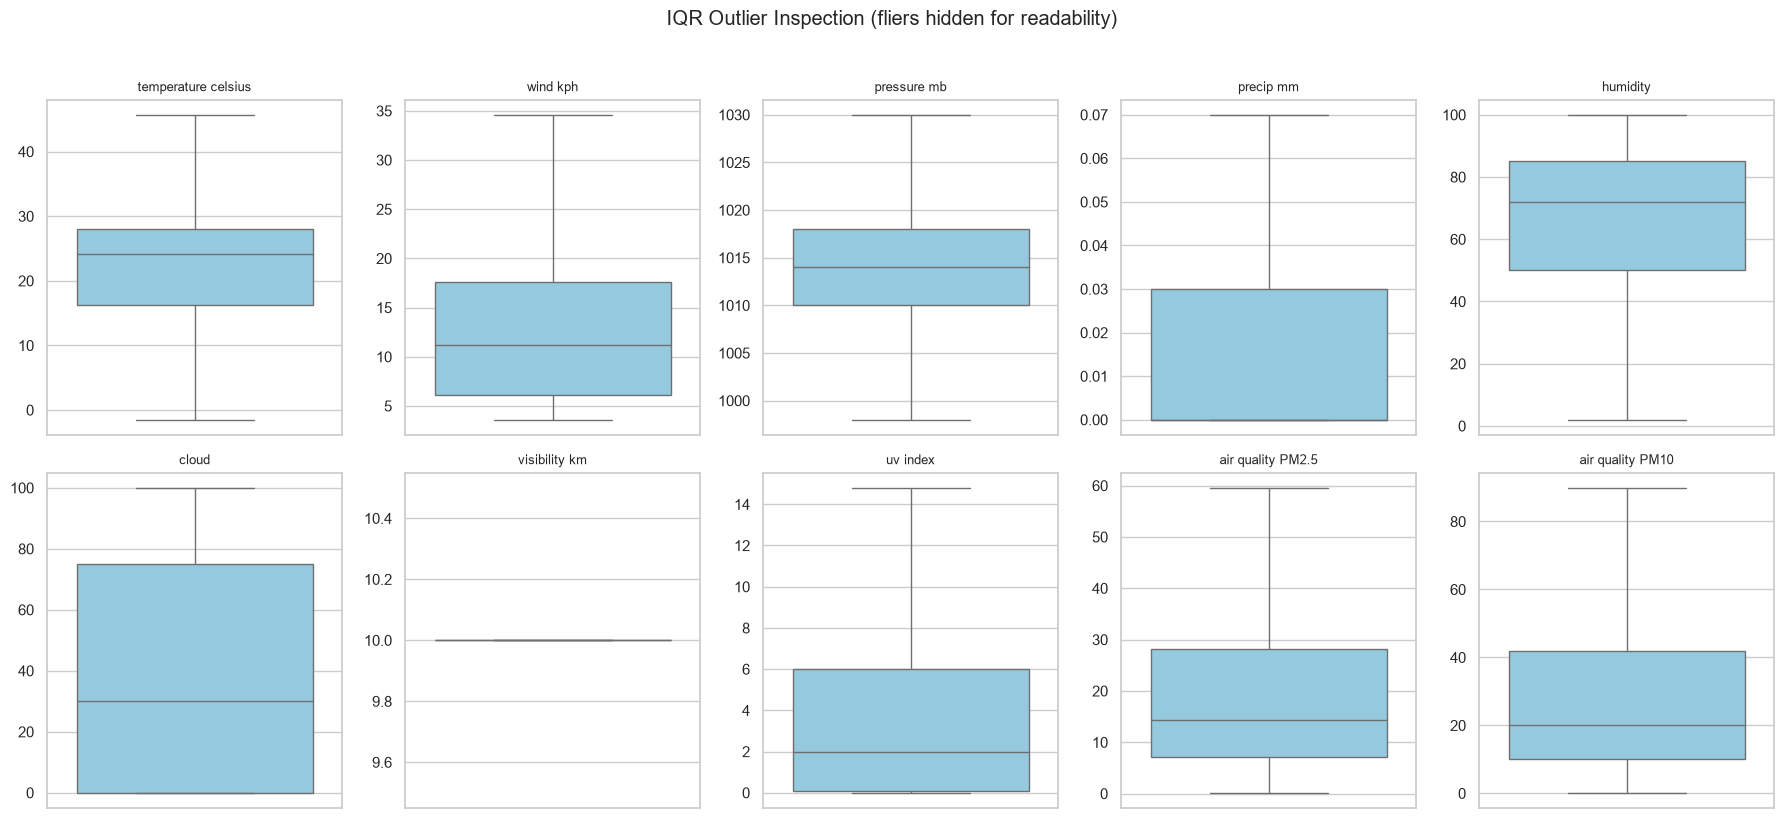

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, column in zip(axes.flat, analysis_features):
    sns.boxplot(y=df[column], ax=ax, color="skyblue", showfliers=False)
    ax.set_title(column.replace("_", " "), fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("IQR Outlier Inspection (fliers hidden for readability)", y=1.02)
plt.tight_layout()
plt.show()

## 7. Exploratory Data Analysis (EDA)

In [16]:
print("Descriptive statistics for key weather variables:")
display(df[analysis_features].describe().T.round(2))

print("\nMost frequent weather conditions:")
condition_counts = df["condition_text"].astype(str).str.strip().str.lower().value_counts().head(15)
display(condition_counts.to_frame("observations"))

Descriptive statistics for key weather variables:


,count,mean,std,min,25%,50%,75%,max
temperature_celsius,"128,638.000",21.450,9.670,-29.800,16.200,24.100,28.000,49.200
wind_kph,"128,638.000",12.930,8.350,3.600,6.100,11.200,17.600,172.100
pressure_mb,"128,638.000","1,014.070",7.020,947.000,"1,010.000","1,014.000","1,018.000","1,080.000"
precip_mm,"128,638.000",0.140,0.570,0.000,0.000,0.000,0.030,42.240
humidity,"128,638.000",66.340,24.010,2.000,50.000,72.000,85.000,100.000
cloud,"128,638.000",40.000,34.100,0.000,0.000,30.000,75.000,100.000
visibility_km,"128,638.000",9.510,2.680,0.000,10.000,10.000,10.000,32.000
uv_index,"128,638.000",3.400,3.560,0.000,0.100,2.000,6.000,16.300
air_quality_PM2.5,"128,638.000",24.520,37.530,0.170,7.150,14.240,28.120,"1,614.100"
air_quality_PM10,"128,638.000",49.150,151.350,0.170,10.000,20.160,42.000,"6,037.290"



Most frequent weather conditions:


,observations
condition_text,
partly cloudy,45405
sunny,37237
patchy rain nearby,10582
overcast,6913
clear,6593
mist,5361
light rain,4027
light rain shower,2962
fog,1588


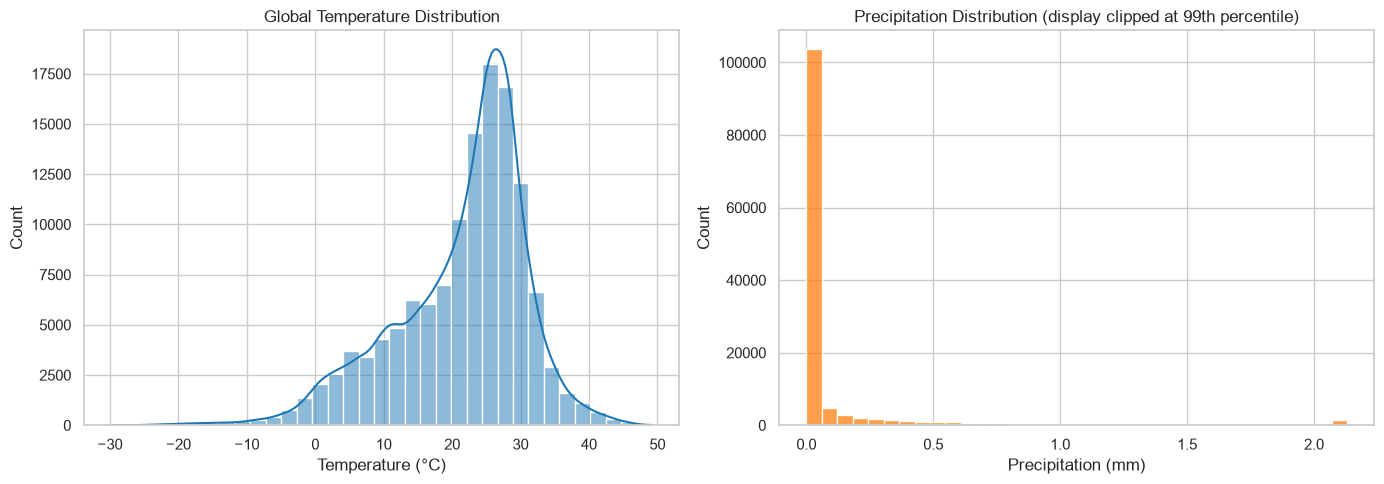

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["temperature_celsius"], bins=35, kde=True, color="#1f77b4", ax=axes[0])
axes[0].set_title("Global Temperature Distribution")
axes[0].set_xlabel("Temperature (°C)")

# Clip only the chart display at the 99th percentile; source values remain unchanged.
precip_display = df["precip_mm"].clip(upper=df["precip_mm"].quantile(0.99))
sns.histplot(precip_display, bins=35, color="#ff7f0e", ax=axes[1])
axes[1].set_title("Precipitation Distribution (display clipped at 99th percentile)")
axes[1].set_xlabel("Precipitation (mm)")
plt.tight_layout()
plt.show()

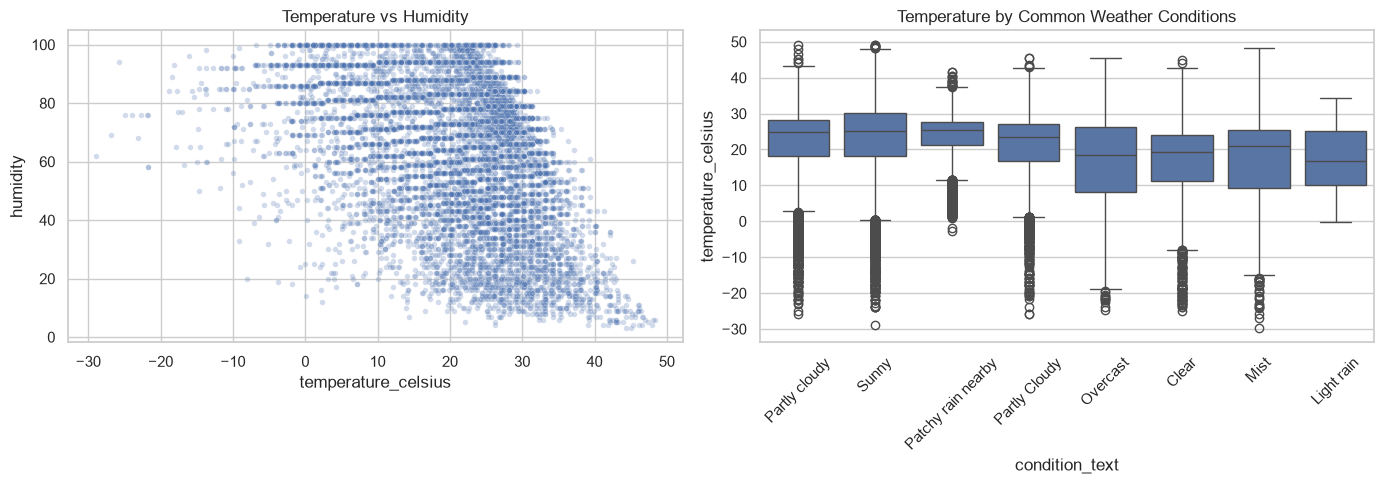

In [18]:
plot_sample = df.sample(min(12000, len(df)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=plot_sample, x="temperature_celsius", y="humidity", alpha=0.25, s=16, ax=axes[0])
axes[0].set_title("Temperature vs Humidity")
sns.boxplot(data=df, x="condition_text", y="temperature_celsius", order=df["condition_text"].value_counts().head(8).index, ax=axes[1])
axes[1].set_title("Temperature by Common Weather Conditions")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

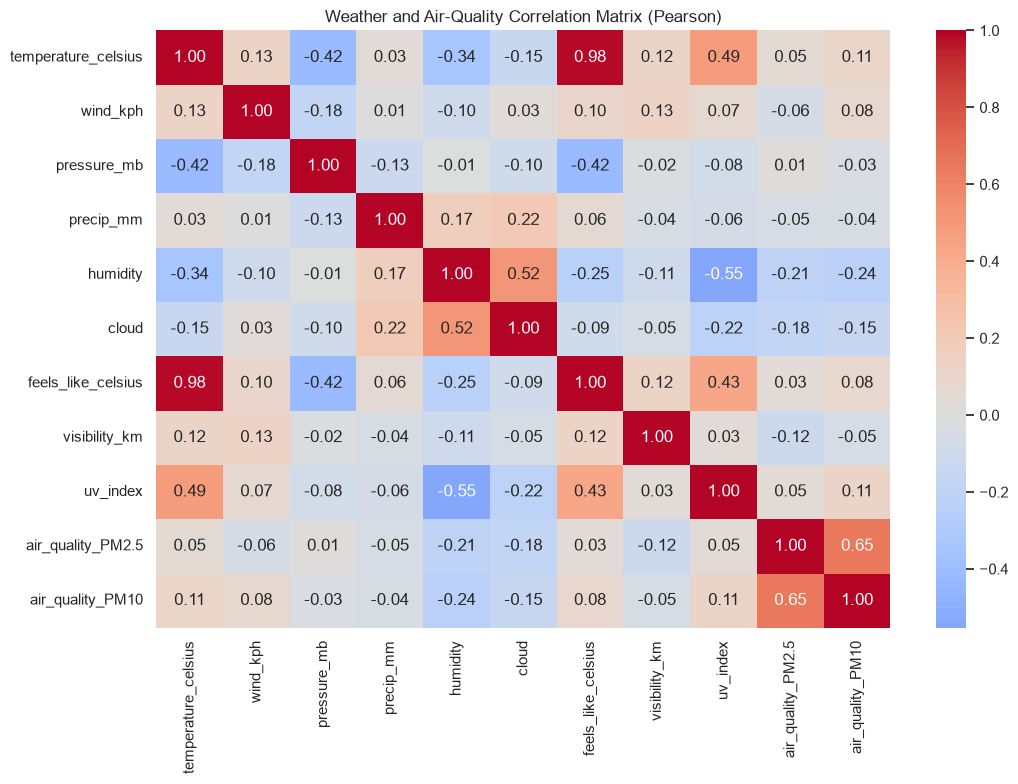

In [19]:
correlation_columns = [
    "temperature_celsius", "wind_kph", "pressure_mb", "precip_mm",
    "humidity", "cloud", "feels_like_celsius", "visibility_km", "uv_index",
    "air_quality_PM2.5", "air_quality_PM10"
]
correlation_matrix = df[correlation_columns].corr(method="pearson")
plt.figure(figsize=(11, 8))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f", square=False)
plt.title("Weather and Air-Quality Correlation Matrix (Pearson)")
plt.tight_layout()
plt.show()

## 8. Advanced EDA: anomaly detection

In [20]:
from sklearn.impute import SimpleImputer

anomaly_features = [
    "temperature_celsius", "wind_kph", "pressure_mb", "precip_mm",
    "humidity", "cloud", "visibility_km", "uv_index",
    "air_quality_PM2.5", "air_quality_PM10"
]
X_anomaly = df[anomaly_features].copy()
X_anomaly_scaled = StandardScaler().fit_transform(X_anomaly)

isolation_forest = IsolationForest(
    n_estimators=150, contamination=0.02,
    random_state=RANDOM_STATE, n_jobs=-1
)
df["anomaly_label"] = isolation_forest.fit_predict(X_anomaly_scaled)
df["anomaly_status"] = df["anomaly_label"].map({1: "Normal", -1: "Anomaly"})

anomaly_counts = df["anomaly_status"].value_counts().rename_axis("status").to_frame("observations")
anomaly_counts["percentage"] = 100 * anomaly_counts["observations"] / len(df)
display(anomaly_counts.round(2))

,observations,percentage
status,,
Normal,126065,98.000
Anomaly,2573,2.000


anomaly_status,Anomaly,Normal
temperature_celsius,23.130,21.410
wind_kph,18.960,12.810
pressure_mb,"1,009.820","1,014.150"
precip_mm,1.280,0.110
humidity,55.400,66.560
air_quality_PM2.5,140.000,22.160
air_quality_PM10,557.140,38.780


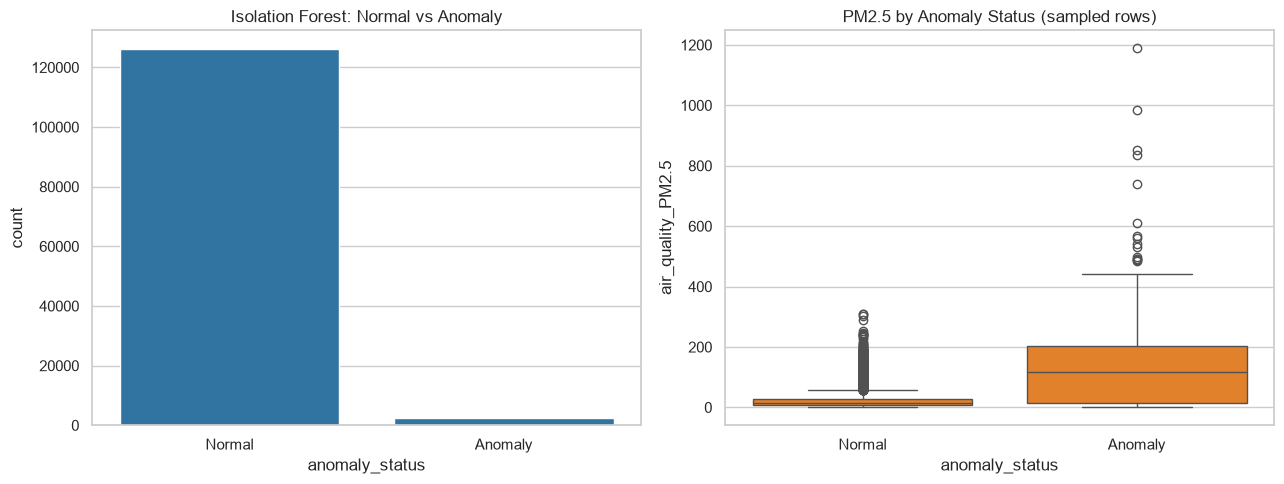

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=df, x="anomaly_status", order=["Normal", "Anomaly"], color="#1f77b4", ax=axes[0])
axes[0].set_title("Isolation Forest: Normal vs Anomaly")

comparison_features = ["temperature_celsius", "wind_kph", "pressure_mb", "precip_mm", "humidity", "air_quality_PM2.5", "air_quality_PM10"]
anomaly_means = df.groupby("anomaly_status")[comparison_features].mean().T
display(anomaly_means.round(2))
sns.boxplot(data=df.sample(min(15000, len(df)), random_state=RANDOM_STATE), x="anomaly_status", y="air_quality_PM2.5", color="#ff7f0e", ax=axes[1])
axes[1].set_title("PM2.5 by Anomaly Status (sampled rows)")
plt.tight_layout()
plt.show()

## 9. Time-series preparation using `last_updated`

In [22]:
location_coverage = (
    df.groupby("location_name")
      .agg(observations=("temperature_celsius", "count"),
           unique_days=("last_updated", lambda values: values.dt.date.nunique()),
           first_date=("last_updated", "min"), last_date=("last_updated", "max"))
      .sort_values("unique_days", ascending=False)
)
print("Locations with the most daily coverage:")
display(location_coverage.head(10))

# Keep the location used in the earlier project work for continuity.
selected_location = "Vatican City"
city_df = df.loc[df["location_name"].eq(selected_location)].copy()
if city_df.empty:
    raise ValueError(f"Selected location {selected_location!r} is not present in the dataset.")
city_df = city_df.sort_values("last_updated").set_index("last_updated")

daily_temperature = city_df["temperature_celsius"].resample("D").mean()
missing_daily_dates = daily_temperature[daily_temperature.isna()]
daily_temperature_clean = daily_temperature.interpolate(method="time")

print("Selected location:", selected_location)
print("Expected daily dates:", len(daily_temperature))
print("Missing daily observations before interpolation:", len(missing_daily_dates))
print("Missing after interpolation:", int(daily_temperature_clean.isna().sum()))
print("Time series:", daily_temperature_clean.index.min(), "to", daily_temperature_clean.index.max())

Locations with the most daily coverage:


,observations,unique_days,first_date,last_date
location_name,,,,
Vatican City,662,661,2024-05-16 10:45:00,2026-03-10 08:00:00
Valletta,662,661,2024-05-16 10:45:00,2026-03-10 08:00:00
Suva,662,661,2024-05-16 20:45:00,2026-03-10 19:00:00
Tashkent,662,661,2024-05-16 13:45:00,2026-03-10 12:00:00
Asmara,662,661,2024-05-16 11:45:00,2026-03-10 10:00:00
Baghdad,662,661,2024-05-16 11:45:00,2026-03-10 10:00:00
Bujumbura,662,661,2024-05-16 10:45:00,2026-03-10 09:00:00
Bern,662,661,2024-05-16 10:45:00,2026-03-10 08:00:00
Kabul,662,661,2024-05-16 13:15:00,2026-03-10 11:30:00


Selected location: Vatican City
Expected daily dates: 664
Missing daily observations before interpolation: 3
Missing after interpolation: 0
Time series: 2024-05-16 00:00:00 to 2026-03-10 00:00:00


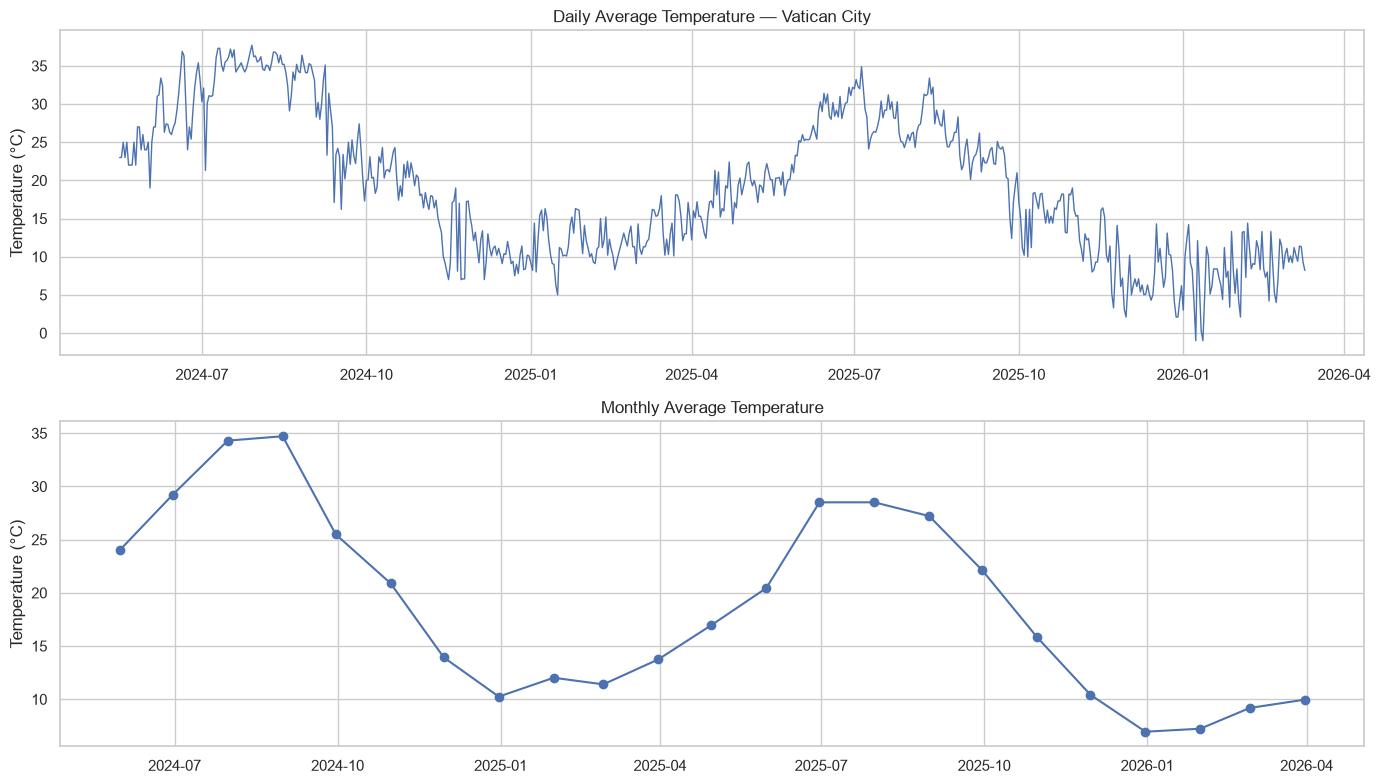

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].plot(daily_temperature_clean.index, daily_temperature_clean.values, linewidth=1)
axes[0].set_title(f"Daily Average Temperature — {selected_location}")
axes[0].set_ylabel("Temperature (°C)")
monthly_temperature = daily_temperature_clean.resample("ME").mean()
axes[1].plot(monthly_temperature.index, monthly_temperature.values, marker="o", linewidth=1.5)
axes[1].set_title("Monthly Average Temperature")
axes[1].set_ylabel("Temperature (°C)")
plt.tight_layout()
plt.show()

## 10. Forecast feature engineering and chronological split

In [24]:
forecast_df = pd.DataFrame(index=daily_temperature_clean.index)
forecast_df["target"] = daily_temperature_clean

for lag in [1, 2, 3, 7, 14, 30]:
    forecast_df[f"lag_{lag}"] = daily_temperature_clean.shift(lag)

shifted_temperature = daily_temperature_clean.shift(1)
for window in [3, 7, 14, 30]:
    forecast_df[f"rolling_mean_{window}"] = shifted_temperature.rolling(window).mean()
    forecast_df[f"rolling_std_{window}"] = shifted_temperature.rolling(window).std()

forecast_df["weekday_sin"] = np.sin(2 * np.pi * forecast_df.index.dayofweek / 7)
forecast_df["weekday_cos"] = np.cos(2 * np.pi * forecast_df.index.dayofweek / 7)
day_of_year = forecast_df.index.dayofyear
forecast_df["annual_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
forecast_df["annual_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
forecast_df["time_index"] = np.arange(len(forecast_df))

forecast_df = forecast_df.dropna().copy()
feature_columns = [column for column in forecast_df.columns if column != "target"]
X = forecast_df[feature_columns]
y = forecast_df["target"]

split_index = int(len(forecast_df) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# All models will be scored on this exact same test index.
training_series = daily_temperature_clean.loc[:y_test.index[0] - pd.Timedelta(days=1)]
test_series = daily_temperature_clean.loc[y_test.index]

print("Feature matrix:", X.shape)
print("Training features:", X_train.shape, "Testing features:", X_test.shape)
print("Training targets:", y_train.index.min(), "to", y_train.index.max())
print("Test targets:", y_test.index.min(), "to", y_test.index.max())
print("Test rows for every model:", len(y_test))

Feature matrix: (634, 19)
Training features: (507, 19) Testing features: (127, 19)
Training targets: 2024-06-15 00:00:00 to 2025-11-03 00:00:00
Test targets: 2025-11-04 00:00:00 to 2026-03-10 00:00:00
Test rows for every model: 127


C:\Users\rohit\AppData\Local\Temp\ipykernel_6404\2292389454.py:12: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  forecast_df["weekday_sin"] = np.sin(2 * np.pi * forecast_df.index.dayofweek / 7)
C:\Users\rohit\AppData\Local\Temp\ipykernel_6404\2292389454.py:13: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  forecast_df["weekday_cos"] = np.cos(2 * np.pi * forecast_df.index.dayofweek / 7)
C:\Users\rohit\AppData\Local\Temp\ipykernel_6404\2292389454.py:14: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  day_of_year = forecast_df.index.dayofyear


## 11. Forecast model 1: persistence baselines

In [25]:
# Baselines are important: a complex model should outperform a simple forecast.
naive_predictions = X_test["lag_1"].to_numpy()
weekly_naive_predictions = X_test["lag_7"].to_numpy()
print("Previous-day baseline MAE:", round(mean_absolute_error(y_test, naive_predictions), 3))
print("7-day seasonal-naive MAE:", round(mean_absolute_error(y_test, weekly_naive_predictions), 3))

Previous-day baseline MAE: 2.827
7-day seasonal-naive MAE: 3.879


## 12. Forecast model 2: cross-validated Ridge regression

In [26]:
# Standardization is fitted inside each CV fold via the pipeline (no scaling leakage).
ridge_pipeline = make_pipeline(StandardScaler(), Ridge())
time_cv = TimeSeriesSplit(n_splits=5)
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"ridge__alpha": [0.1, 0.3, 1, 3, 10, 30, 100]},
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=-1
)
ridge_search.fit(X_train, y_train)
ridge_model = ridge_search.best_estimator_
ridge_predictions = ridge_model.predict(X_test)
print("Best Ridge parameters:", ridge_search.best_params_)
print("Best training CV MAE:", round(-ridge_search.best_score_, 4))

Best Ridge parameters: {'ridge__alpha': 10}
Best training CV MAE: 1.9901


## 13. Forecast models 3 and 4: Random Forest and XGBoost

In [27]:
rf_model = RandomForestRegressor(
    n_estimators=250, max_depth=8, min_samples_split=10,
    min_samples_leaf=5, max_features=0.8,
    random_state=RANDOM_STATE, n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

xgb_model = XGBRegressor(
    n_estimators=250, learning_rate=0.025, max_depth=2,
    min_child_weight=8, subsample=0.8, colsample_bytree=0.8,
    reg_lambda=8, objective="reg:squarederror",
    random_state=RANDOM_STATE, n_jobs=4
)
xgb_model.fit(X_train, y_train)
xgb_predictions = xgb_model.predict(X_test)
print("Random Forest and XGBoost fitted on the same training period.")

Random Forest and XGBoost fitted on the same training period.


## 14. Forecast models 5 and 6: ARIMA and Exponential Smoothing

In [28]:
# Rolling one-step-ahead ARIMA evaluation.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    arima_fit = ARIMA(training_series, order=(5, 1, 0)).fit()
    arima_predictions = []
    for date, actual_value in test_series.items():
        next_prediction = float(np.asarray(arima_fit.forecast(steps=1))[0])
        arima_predictions.append(next_prediction)
        arima_fit = arima_fit.append([float(actual_value)], refit=False)

# Rolling one-step-ahead additive-trend Exponential Smoothing.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    history = training_series.copy()
    exp_smoothing_predictions = []
    for date, actual_value in test_series.items():
        es_fit = ExponentialSmoothing(
            history, trend="add", seasonal=None,
            initialization_method="estimated"
        ).fit(optimized=True)
        next_prediction = float(np.asarray(es_fit.forecast(steps=1))[0])
        exp_smoothing_predictions.append(next_prediction)
        history.loc[date] = actual_value

arima_predictions = np.asarray(arima_predictions)
exp_smoothing_predictions = np.asarray(exp_smoothing_predictions)
print("ARIMA predictions:", len(arima_predictions))
print("Exponential Smoothing predictions:", len(exp_smoothing_predictions))

ARIMA predictions: 127
Exponential Smoothing predictions: 127


## 15. Ensemble model: Ridge + XGBoost

In [29]:
blend_cv = TimeSeriesSplit(n_splits=5)
oof_ridge = np.full(len(X_train), np.nan)
oof_xgb = np.full(len(X_train), np.nan)

for fold_train_idx, fold_valid_idx in blend_cv.split(X_train):
    X_fold_train = X_train.iloc[fold_train_idx]
    y_fold_train = y_train.iloc[fold_train_idx]
    X_fold_valid = X_train.iloc[fold_valid_idx]

    # Tune Ridge inside each outer fold to keep the validation predictions chronological.
    inner_search = GridSearchCV(
        make_pipeline(StandardScaler(), Ridge()),
        {"ridge__alpha": [0.3, 1, 3, 10, 30]},
        scoring="neg_mean_absolute_error",
        cv=TimeSeriesSplit(n_splits=3),
        n_jobs=-1
    )
    inner_search.fit(X_fold_train, y_fold_train)
    fold_ridge = inner_search.best_estimator_
    fold_xgb = XGBRegressor(
        n_estimators=250, learning_rate=0.025, max_depth=2,
        min_child_weight=8, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=8, objective="reg:squarederror",
        random_state=RANDOM_STATE, n_jobs=4
    )
    fold_xgb.fit(X_fold_train, y_fold_train)
    oof_ridge[fold_valid_idx] = fold_ridge.predict(X_fold_valid)
    oof_xgb[fold_valid_idx] = fold_xgb.predict(X_fold_valid)

valid_oof = np.isfinite(oof_ridge) & np.isfinite(oof_xgb)
candidate_ridge_weights = [0.50, 0.60, 0.70, 0.80, 0.90]
blend_validation = []
for ridge_weight in candidate_ridge_weights:
    candidate_prediction = (
        ridge_weight * oof_ridge[valid_oof]
        + (1 - ridge_weight) * oof_xgb[valid_oof]
    )
    blend_validation.append({
        "Ridge weight": ridge_weight,
        "XGBoost weight": 1 - ridge_weight,
        "Validation MAE": mean_absolute_error(y_train.iloc[valid_oof], candidate_prediction)
    })
blend_validation = pd.DataFrame(blend_validation).sort_values("Validation MAE")
best_ridge_weight = float(blend_validation.iloc[0]["Ridge weight"])
print("Training-only blend-weight validation:")
display(blend_validation.round(4))
print("Selected Ridge weight:", best_ridge_weight)

ensemble_predictions = (
    best_ridge_weight * ridge_predictions
    + (1 - best_ridge_weight) * xgb_predictions
)

Training-only blend-weight validation:


,Ridge weight,XGBoost weight,Validation MAE
4,0.900,0.100,2.374
3,0.800,0.200,2.608
2,0.700,0.300,2.870
1,0.600,0.400,3.143
0,0.500,0.500,3.429


Selected Ridge weight: 0.9


## 16. Model comparison on a common test period

In [30]:
prediction_sets = {
    "Naive (previous day)": naive_predictions,
    "Seasonal naive (7 days)": weekly_naive_predictions,
    "Linear Regression (Ridge CV tuned)": ridge_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions,
    "ARIMA (rolling 1-step)": arima_predictions,
    "Exponential Smoothing (rolling 1-step)": exp_smoothing_predictions,
    "Ensemble (Ridge + XGBoost)": ensemble_predictions
}

metric_rows = []
for model_name, predictions in prediction_sets.items():
    metric_rows.append({
        "Model": model_name,
        "MAE (°C)": mean_absolute_error(y_test, predictions),
        "RMSE (°C)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

model_comparison = pd.DataFrame(metric_rows).sort_values("MAE (°C)").reset_index(drop=True)
model_comparison.insert(0, "Rank", np.arange(1, len(model_comparison) + 1))
display(model_comparison.round(4))

best_model_name = model_comparison.loc[0, "Model"]
best_predictions = prediction_sets[best_model_name]
print("Best model by holdout MAE:", best_model_name)

,Rank,Model,MAE (°C),RMSE (°C),R2
0,1,Ensemble (Ridge + XGBoost),2.476,3.225,0.152
1,2,Linear Regression (Ridge CV tuned),2.504,3.332,0.095
2,3,ARIMA (rolling 1-step),2.688,3.468,0.019
3,4,Exponential Smoothing (rolling 1-step),2.709,3.492,0.006
4,5,Naive (previous day),2.827,3.696,-0.114
5,6,XGBoost,3.748,4.553,-0.690
6,7,Seasonal naive (7 days),3.879,4.922,-0.975
7,8,Random Forest,4.756,5.585,-1.543


Best model by holdout MAE: Ensemble (Ridge + XGBoost)


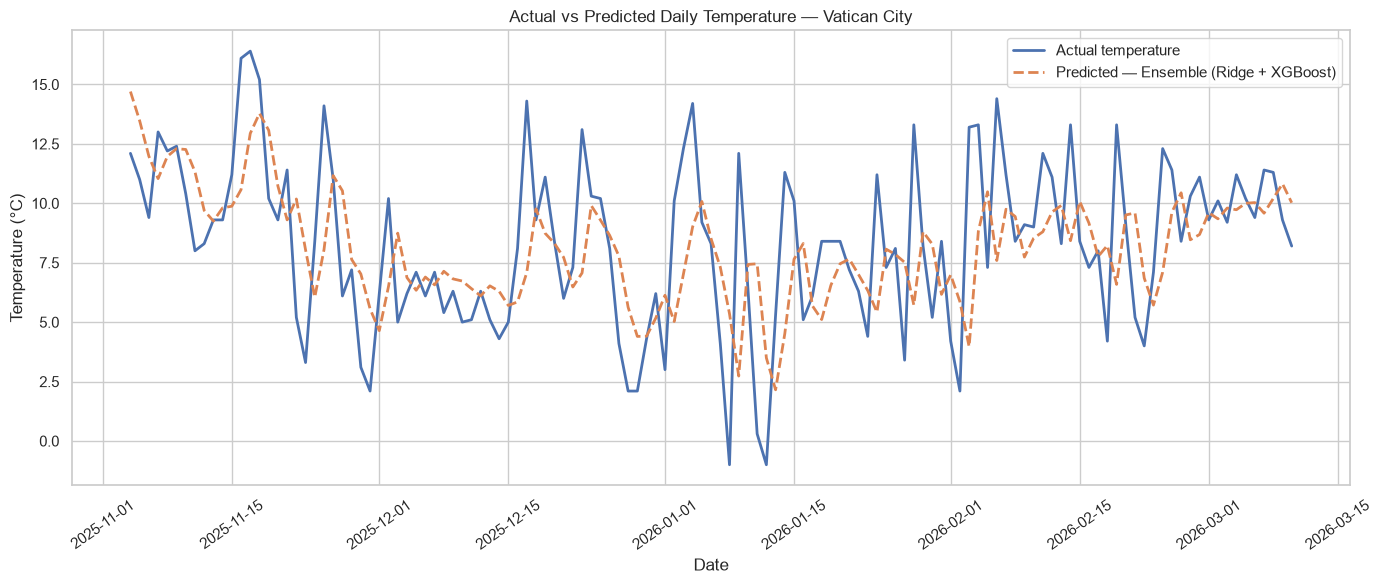

In [31]:
plt.figure(figsize=(14, 6))
plt.plot(y_test.index, y_test.values, label="Actual temperature", linewidth=2)
plt.plot(y_test.index, best_predictions, label=f"Predicted — {best_model_name}", linestyle="--", linewidth=2)
plt.title(f"Actual vs Predicted Daily Temperature — {selected_location}")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=35)
plt.legend()
plt.tight_layout()
plt.show()

## 17. Feature importance: two techniques

Random Forest built-in feature importance:


,Feature,RF importance
6,rolling_mean_3,0.387
0,lag_1,0.377
8,rolling_mean_7,0.138
10,rolling_mean_14,0.032
1,lag_2,0.017
18,time_index,0.014
17,annual_cos,0.009
16,annual_sin,0.004
7,rolling_std_3,0.003
2,lag_3,0.003


Permutation importance for Ridge (larger positive values indicate greater reliance):


,Feature,Permutation importance (MAE increase),Standard deviation
0,lag_1,0.349,0.113
17,annual_cos,0.053,0.044
2,lag_3,0.051,0.031
5,lag_30,0.023,0.011
14,weekday_sin,0.006,0.005
15,weekday_cos,0.001,0.002
7,rolling_std_3,0.000,0.001
13,rolling_std_30,-0.000,0.000
4,lag_14,-0.001,0.001
11,rolling_std_14,-0.003,0.004


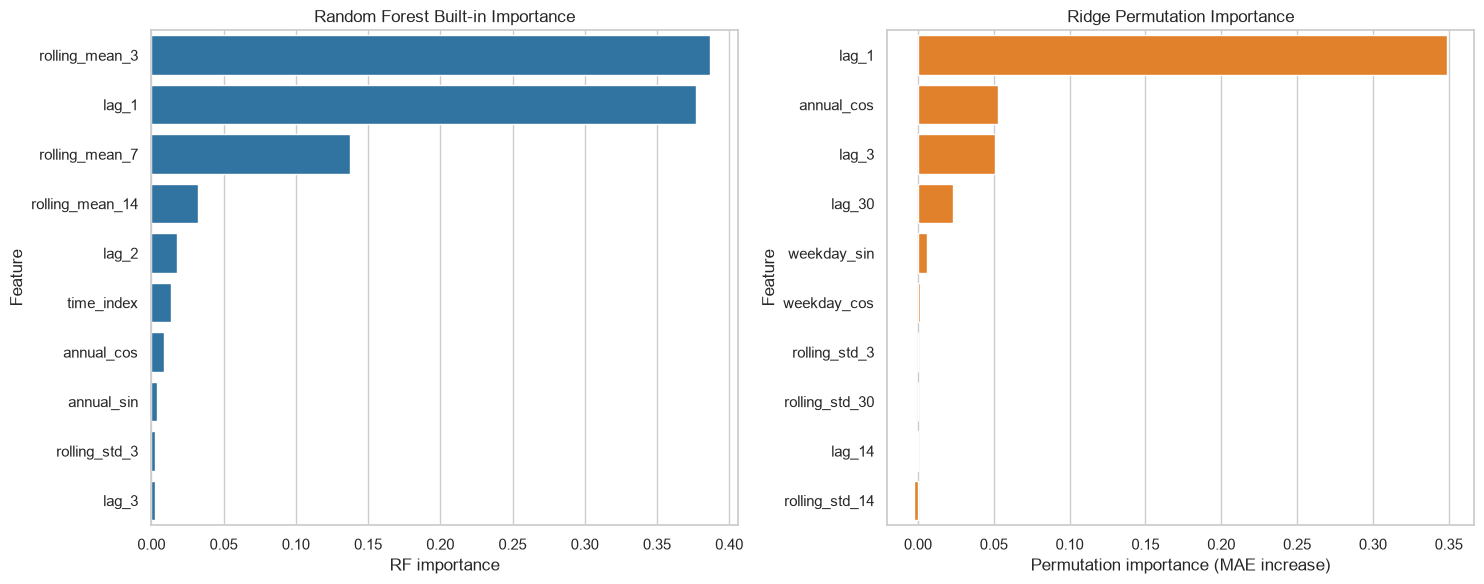

In [32]:
# Technique 1: impurity-based importance from the fitted Random Forest.
rf_importance = pd.DataFrame({
    "Feature": feature_columns,
    "RF importance": rf_model.feature_importances_
}).sort_values("RF importance", ascending=False)
print("Random Forest built-in feature importance:")
display(rf_importance.head(12).round(4))

# Technique 2: permutation importance for the selected Ridge model on held-out data.
permutation_result = permutation_importance(
    ridge_model, X_test, y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
permutation_importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Permutation importance (MAE increase)": permutation_result.importances_mean,
    "Standard deviation": permutation_result.importances_std
}).sort_values("Permutation importance (MAE increase)", ascending=False)
print("Permutation importance for Ridge (larger positive values indicate greater reliance):")
display(permutation_importance_df.head(12).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=rf_importance.head(10), x="RF importance", y="Feature", color="#1f77b4", ax=axes[0])
axes[0].set_title("Random Forest Built-in Importance")
sns.barplot(data=permutation_importance_df.head(10), x="Permutation importance (MAE increase)", y="Feature", color="#ff7f0e", ax=axes[1])
axes[1].set_title("Ridge Permutation Importance")
plt.tight_layout()
plt.show()

## 18. Unique Analysis A — Climate patterns

Country labels are standardized because the source includes multilingual variants (for example, different spellings of the same country). The country-to-continent lookup is explicit for the country labels present in this repository. These are dataset aggregates; they are not official climate normals.

Country labels without continent mapping: []
Rows retained for stable-location geographic summaries: 128351
Location/country pairs retained: 211
Global monthly average temperature:


,Month,Average temperature (°C)
0,January,16.060
1,February,16.700
2,March,19.290
3,April,21.970
4,May,23.980
5,June,25.720
6,July,26.020
7,August,25.750
8,September,24.250
9,October,21.600


Yearly summary (note partial years):


C:\Users\rohit\AppData\Local\Temp\ipykernel_6404\483168065.py:43: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(yearly_climate.round(2))


,average_temperature,observations,first_observation,last_observation
year,,,,
2024,23.610,44239,2024-05-16 02:45:00,2024-12-31 23:30:00
2025,21.190,71082,2025-01-01 02:00:00,2025-12-31 23:15:00
2026,15.470,13030,2026-01-01 01:00:00,2026-03-10 20:00:00


Warmest country averages in this dataset (minimum 30 observations):


,,average_temperature,observations
country_standard,continent,,
United Arab Emirates,Asia,32.510,661
Qatar,Asia,32.470,659
Djibouti,Africa,31.560,659
Oman,Asia,31.470,661
Cambodia,Asia,31.360,659
Kuwait,Asia,31.310,659
Saudi Arabia,Asia,30.950,660
Thailand,Asia,30.780,1322
Bangladesh,Asia,30.750,660


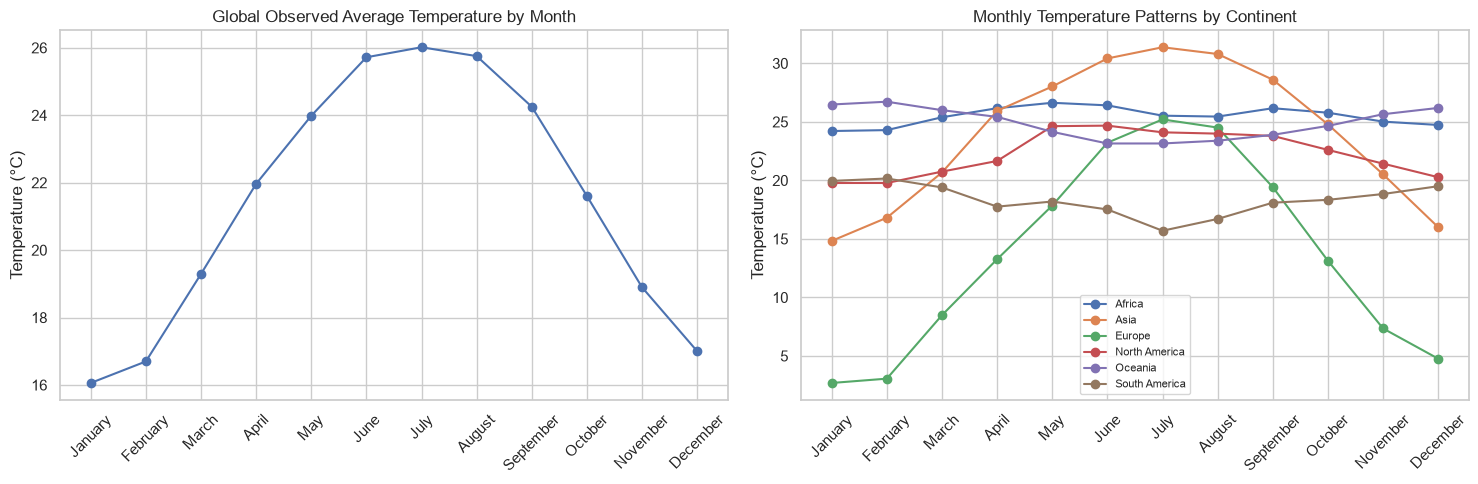

In [33]:
country_aliases = {'Bélgica': 'Belgium', 'Estonie': 'Estonia', 'Inde': 'India', 'Jemen': 'Yemen', 'Komoren': 'Comoros', 'Kyrghyzstan': 'Kyrgyzstan', 'Letonia': 'Latvia', 'Malásia': 'Malaysia', 'Marrocos': 'Morocco', 'Mexique': 'Mexico', 'Polônia': 'Poland', 'Saudi Arabien': 'Saudi Arabia', 'Turkménistan': 'Turkmenistan', 'Турция': 'Turkey', 'Гватемала': 'Guatemala', 'Польша': 'Poland', 'كولومبيا': 'Colombia', '火鸡': 'Turkey', 'Südkorea': 'South Korea', 'Saint-Vincent-et-les-Grenadines': 'Saint Vincent and the Grenadines', 'USA United States of America': 'United States', 'Bahamas': 'The Bahamas', "Cote d'Ivoire": 'Ivory Coast', 'Democratic Republic of Congo': 'Democratic Republic of the Congo', 'Congo': 'Republic of the Congo', 'Fiji Islands': 'Fiji', 'Brunei Darussalam': 'Brunei', 'Macedonia': 'North Macedonia', 'Seychelles Islands': 'Seychelles', "Lao People's Democratic Republic": 'Laos', 'Micronesia': 'Federated States of Micronesia', 'United States of America': 'United States'}
continent_lookup = {'Afghanistan': 'Asia', 'Albania': 'Europe', 'Algeria': 'Africa', 'Andorra': 'Europe', 'Angola': 'Africa', 'Antigua and Barbuda': 'North America', 'Argentina': 'South America', 'Armenia': 'Asia', 'Australia': 'Oceania', 'Austria': 'Europe', 'Azerbaijan': 'Asia', 'The Bahamas': 'North America', 'Bahrain': 'Asia', 'Bangladesh': 'Asia', 'Barbados': 'North America', 'Belarus': 'Europe', 'Belgium': 'Europe', 'Belize': 'North America', 'Benin': 'Africa', 'Bhutan': 'Asia', 'Bolivia': 'South America', 'Bosnia and Herzegovina': 'Europe', 'Botswana': 'Africa', 'Brazil': 'South America', 'Brunei': 'Asia', 'Bulgaria': 'Europe', 'Burkina Faso': 'Africa', 'Burundi': 'Africa', 'Cambodia': 'Asia', 'Cameroon': 'Africa', 'Canada': 'North America', 'Cape Verde': 'Africa', 'Central African Republic': 'Africa', 'Chad': 'Africa', 'Chile': 'South America', 'China': 'Asia', 'Colombia': 'South America', 'Comoros': 'Africa', 'Republic of the Congo': 'Africa', 'Costa Rica': 'North America', 'Ivory Coast': 'Africa', 'Croatia': 'Europe', 'Cuba': 'North America', 'Cyprus': 'Europe', 'Czech Republic': 'Europe', 'Democratic Republic of the Congo': 'Africa', 'Denmark': 'Europe', 'Djibouti': 'Africa', 'Dominica': 'North America', 'Dominican Republic': 'North America', 'Ecuador': 'South America', 'Egypt': 'Africa', 'El Salvador': 'North America', 'Equatorial Guinea': 'Africa', 'Eritrea': 'Africa', 'Estonia': 'Europe', 'Ethiopia': 'Africa', 'Fiji': 'Oceania', 'Finland': 'Europe', 'France': 'Europe', 'Gabon': 'Africa', 'Gambia': 'Africa', 'Georgia': 'Asia', 'Germany': 'Europe', 'Ghana': 'Africa', 'Greece': 'Europe', 'Grenada': 'North America', 'Guatemala': 'North America', 'Guinea': 'Africa', 'Guinea-Bissau': 'Africa', 'Guyana': 'South America', 'Haiti': 'North America', 'Honduras': 'North America', 'Hungary': 'Europe', 'Iceland': 'Europe', 'India': 'Asia', 'Indonesia': 'Asia', 'Iran': 'Asia', 'Iraq': 'Asia', 'Ireland': 'Europe', 'Israel': 'Asia', 'Italy': 'Europe', 'Jamaica': 'North America', 'Japan': 'Asia', 'Yemen': 'Asia', 'Jordan': 'Asia', 'Kazakhstan': 'Asia', 'Kenya': 'Africa', 'Kiribati': 'Oceania', 'Kosovo': 'Europe', 'Kuwait': 'Asia', 'Kyrgyzstan': 'Asia', 'Laos': 'Asia', 'Latvia': 'Europe', 'Lebanon': 'Asia', 'Lesotho': 'Africa', 'Liberia': 'Africa', 'Libya': 'Africa', 'Liechtenstein': 'Europe', 'Lithuania': 'Europe', 'Luxembourg': 'Europe', 'North Macedonia': 'Europe', 'Madagascar': 'Africa', 'Malawi': 'Africa', 'Malaysia': 'Asia', 'Maldives': 'Asia', 'Mali': 'Africa', 'Malta': 'Europe', 'Morocco': 'Africa', 'Marshall Islands': 'Oceania', 'Mauritania': 'Africa', 'Mauritius': 'Africa', 'Mexico': 'North America', 'Federated States of Micronesia': 'Oceania', 'Monaco': 'Europe', 'Mongolia': 'Asia', 'Montenegro': 'Europe', 'Mozambique': 'Africa', 'Myanmar': 'Asia', 'Namibia': 'Africa', 'Nepal': 'Asia', 'Netherlands': 'Europe', 'New Zealand': 'Oceania', 'Nicaragua': 'North America', 'Niger': 'Africa', 'Nigeria': 'Africa', 'North Korea': 'Asia', 'Norway': 'Europe', 'Oman': 'Asia', 'Pakistan': 'Asia', 'Palau': 'Oceania', 'Panama': 'North America', 'Papua New Guinea': 'Oceania', 'Paraguay': 'South America', 'Peru': 'South America', 'Philippines': 'Asia', 'Poland': 'Europe', 'Portugal': 'Europe', 'Qatar': 'Asia', 'Romania': 'Europe', 'Russia': 'Europe', 'Rwanda': 'Africa', 'Saint Kitts and Nevis': 'North America', 'Saint Lucia': 'North America', 'Saint Vincent and the Grenadines': 'North America', 'Samoa': 'Oceania', 'San Marino': 'Europe', 'Saudi Arabia': 'Asia', 'Senegal': 'Africa', 'Serbia': 'Europe', 'Seychelles': 'Africa', 'Sierra Leone': 'Africa', 'Singapore': 'Asia', 'Slovakia': 'Europe', 'Slovenia': 'Europe', 'Solomon Islands': 'Oceania', 'Somalia': 'Africa', 'South Africa': 'Africa', 'South Korea': 'Asia', 'Spain': 'Europe', 'Sri Lanka': 'Asia', 'Sudan': 'Africa', 'Suriname': 'South America', 'Swaziland': 'Africa', 'Sweden': 'Europe', 'Switzerland': 'Europe', 'Syria': 'Asia', 'Tajikistan': 'Asia', 'Tanzania': 'Africa', 'Thailand': 'Asia', 'Timor-Leste': 'Asia', 'Togo': 'Africa', 'Tonga': 'Oceania', 'Trinidad and Tobago': 'North America', 'Tunisia': 'Africa', 'Turkey': 'Asia', 'Turkmenistan': 'Asia', 'Tuvalu': 'Oceania', 'United States': 'North America', 'Uganda': 'Africa', 'Ukraine': 'Europe', 'United Arab Emirates': 'Asia', 'United Kingdom': 'Europe', 'Uruguay': 'South America', 'Uzbekistan': 'Asia', 'Vanuatu': 'Oceania', 'Vatican City': 'Europe', 'Venezuela': 'South America', 'Vietnam': 'Asia', 'Zambia': 'Africa', 'Zimbabwe': 'Africa'}

df["country_standard"] = df["country"].replace(country_aliases)
df["continent"] = df["country_standard"].map(continent_lookup)
unknown_continents = sorted(df.loc[df["continent"].isna(), "country_standard"].dropna().unique())
print("Country labels without continent mapping:", unknown_continents)
if unknown_continents:
    raise ValueError("Please add a continent mapping for the listed country labels.")

# Exclude one-off malformed city/country labels from geographic summaries.
# The original cleaned dataframe is retained unchanged for the main EDA and forecasting.
location_counts = (
    df.groupby(["country_standard", "location_name"]).size()
      .rename("location_observations").reset_index()
)
df_geo = df.merge(location_counts, on=["country_standard", "location_name"], how="left")
df_geo = df_geo.loc[df_geo["location_observations"] >= 30].copy()
print("Rows retained for stable-location geographic summaries:", len(df_geo))
print("Location/country pairs retained:", df_geo.groupby(["country_standard", "location_name"]).ngroups)

# Month-of-year means blend both hemispheres; continent-specific monthly lines help reveal differences.
df_geo["month_number"] = df_geo["last_updated"].dt.month
df_geo["year"] = df_geo["last_updated"].dt.year
monthly_global = df_geo.groupby("month_number")["temperature_celsius"].mean().reindex(range(1, 13))
monthly_continent = df_geo.groupby(["continent", "month_number"])["temperature_celsius"].mean().reset_index()
yearly_climate = df_geo.groupby("year").agg(
    average_temperature=("temperature_celsius", "mean"),
    observations=("temperature_celsius", "count"),
    first_observation=("last_updated", "min"),
    last_observation=("last_updated", "max")
)
country_climate = df_geo.groupby(["country_standard", "continent"]).agg(
    average_temperature=("temperature_celsius", "mean"),
    observations=("temperature_celsius", "count")
).sort_values("average_temperature", ascending=False)

month_names = pd.date_range("2024-01-01", periods=12, freq="MS").strftime("%B")
monthly_global_table = pd.DataFrame({"Month": month_names, "Average temperature (°C)": monthly_global.values})
print("Global monthly average temperature:")
display(monthly_global_table.round(2))
print("Yearly summary (note partial years):")
display(yearly_climate.round(2))
print("Warmest country averages in this dataset (minimum 30 observations):")
display(country_climate.loc[country_climate["observations"].ge(30)].head(10).round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(month_names, monthly_global.values, marker="o")
axes[0].set_title("Global Observed Average Temperature by Month")
axes[0].set_ylabel("Temperature (°C)")
axes[0].tick_params(axis="x", rotation=45)
for continent, group in monthly_continent.groupby("continent"):
    group = group.sort_values("month_number")
    axes[1].plot(group["month_number"], group["temperature_celsius"], marker="o", label=continent)
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names, rotation=45)
axes[1].set_title("Monthly Temperature Patterns by Continent")
axes[1].set_ylabel("Temperature (°C)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 19. Unique Analysis B — Environmental impact

Spearman correlation matrix:


,air_quality_PM2.5,air_quality_PM10,temperature_celsius,humidity,wind_kph,precip_mm
air_quality_PM2.5,1.000,0.951,0.066,-0.250,-0.130,-0.244
air_quality_PM10,0.951,1.000,0.127,-0.289,-0.035,-0.253
temperature_celsius,0.066,0.127,1.000,-0.334,0.173,0.043
humidity,-0.250,-0.289,-0.334,1.000,-0.150,0.369
wind_kph,-0.130,-0.035,0.173,-0.150,1.000,0.052
precip_mm,-0.244,-0.253,0.043,0.369,0.052,1.000


Weather-variable associations with PM2.5 and PM10:


,air_quality_PM2.5,air_quality_PM10
temperature_celsius,0.066,0.127
humidity,-0.250,-0.289
wind_kph,-0.130,-0.035
precip_mm,-0.244,-0.253


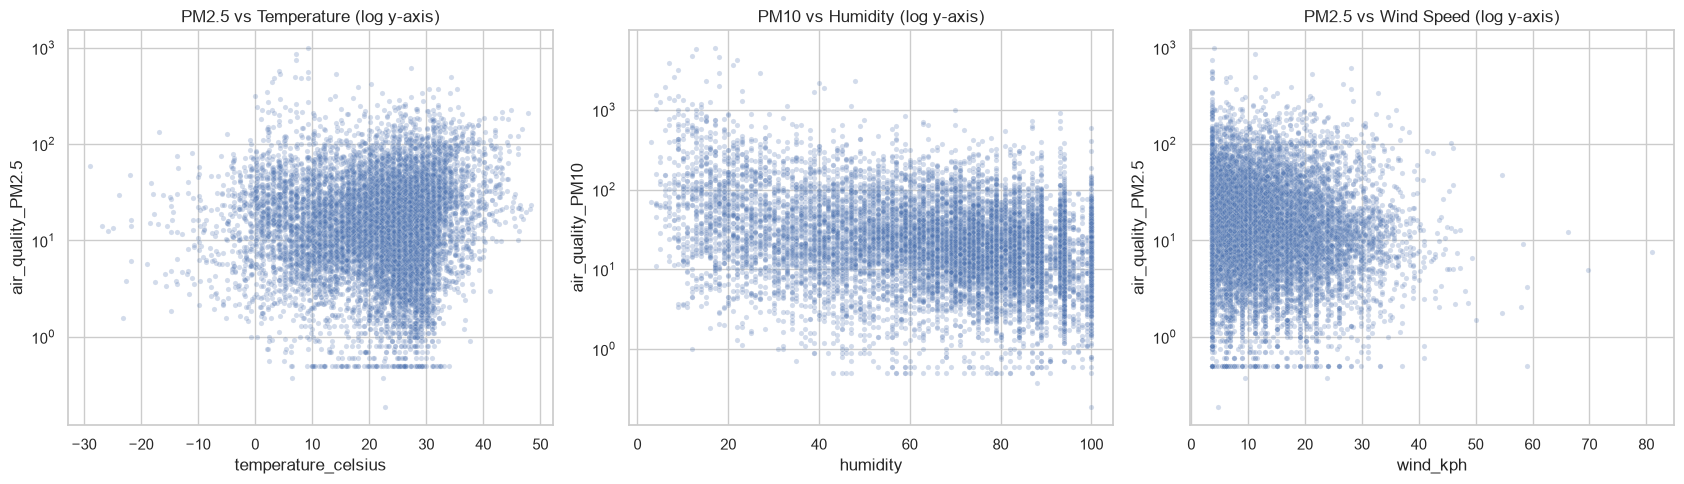

In [34]:
environmental_columns = [
    "air_quality_PM2.5", "air_quality_PM10", "temperature_celsius",
    "humidity", "wind_kph", "precip_mm"
]
environmental_data = df[environmental_columns].copy()
spearman_corr = environmental_data.corr(method="spearman")
print("Spearman correlation matrix:")
display(spearman_corr.round(3))

pollution_associations = spearman_corr[["air_quality_PM2.5", "air_quality_PM10"]].drop(
    index=["air_quality_PM2.5", "air_quality_PM10"]
)
print("Weather-variable associations with PM2.5 and PM10:")
display(pollution_associations.round(3))

sample_env = environmental_data.sample(min(12000, len(environmental_data)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(data=sample_env, x="temperature_celsius", y="air_quality_PM2.5", alpha=0.25, s=14, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("PM2.5 vs Temperature (log y-axis)")
sns.scatterplot(data=sample_env, x="humidity", y="air_quality_PM10", alpha=0.25, s=14, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("PM10 vs Humidity (log y-axis)")
sns.scatterplot(data=sample_env, x="wind_kph", y="air_quality_PM2.5", alpha=0.25, s=14, ax=axes[2])
axes[2].set_yscale("log")
axes[2].set_title("PM2.5 vs Wind Speed (log y-axis)")
plt.tight_layout()
plt.show()

## 20. Unique Analysis C — Spatial analysis

Locations available for spatial analysis: 211


,country_standard,location_name,latitude,longitude,average_temperature,observations
198,United Arab Emirates,Abu Dhabi,24.470,54.370,32.510,661
150,Qatar,Doha,25.290,51.530,32.470,659
50,Djibouti,Djibouti,11.600,43.150,31.560,659
185,Thailand,Bangkok,13.750,100.520,31.530,660
138,Oman,Muscat,23.610,58.590,31.470,661
176,Sudan,Khartoum,15.590,32.530,31.380,659
32,Cambodia,Phnom Penh,11.550,104.920,31.360,659
100,Kuwait,Kuwait City,29.370,47.960,31.310,659
161,Saudi Arabia,Riyadh,24.640,46.770,30.950,660
12,Bangladesh,Dhaka,23.720,90.410,30.750,660


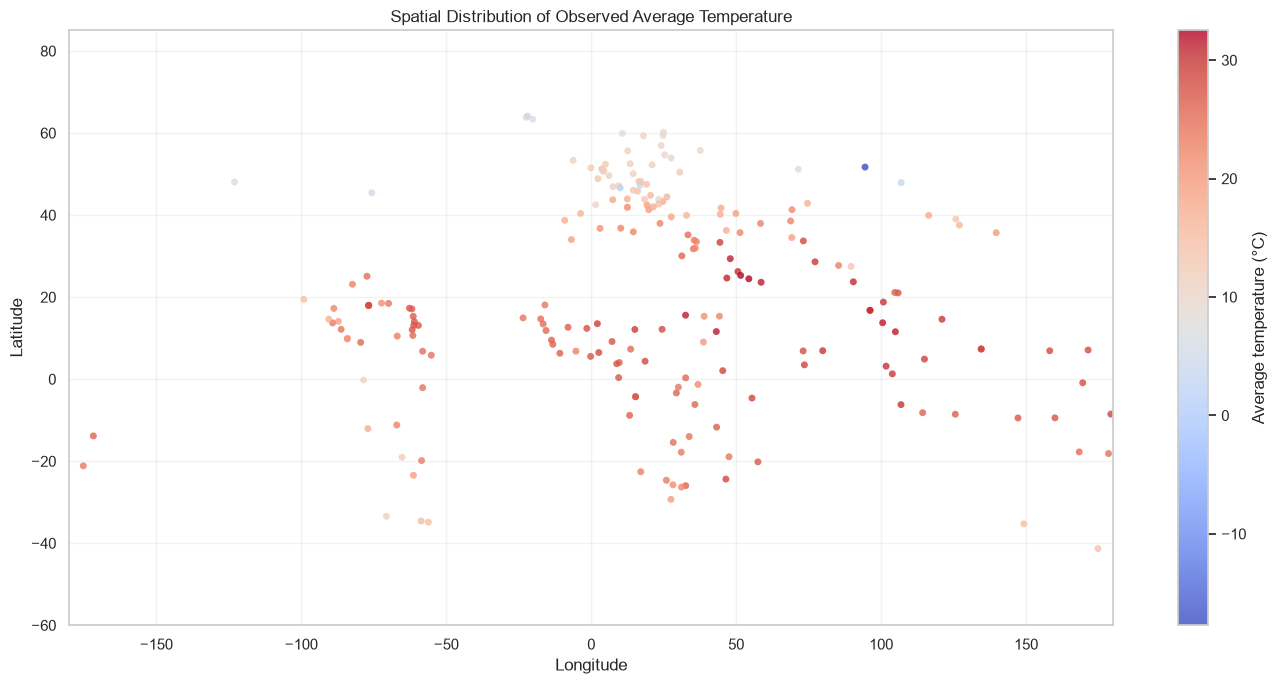

In [35]:
spatial_data = (
    df_geo.groupby(["country_standard", "location_name"])
      .agg(latitude=("latitude", "median"),
           longitude=("longitude", "median"),
           average_temperature=("temperature_celsius", "mean"),
           observations=("temperature_celsius", "count"))
      .reset_index()
)
print("Locations available for spatial analysis:", len(spatial_data))
display(spatial_data.sort_values("average_temperature", ascending=False).head(10).round(2))

plt.figure(figsize=(14, 7))
points = plt.scatter(
    spatial_data["longitude"], spatial_data["latitude"],
    c=spatial_data["average_temperature"], cmap="coolwarm",
    s=25, alpha=0.8, edgecolors="none"
)
plt.colorbar(points, label="Average temperature (°C)")
plt.title("Spatial Distribution of Observed Average Temperature")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.xlim(-180, 180)
plt.ylim(-60, 85)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 21. Unique Analysis D — Geographical patterns by country and continent

Weather comparison by continent:


,average_temperature,average_humidity,average_wind_kph,average_precip_mm,locations,observations
continent,,,,,,
Africa,25.430,61.330,13.170,0.120,53,33632
Oceania,24.860,82.070,17.890,0.290,14,8543
Asia,24.040,52.500,12.660,0.160,52,32706
North America,22.330,84.390,13.110,0.120,26,15074
South America,18.330,82.150,7.620,0.130,13,7825
Europe,13.680,69.310,12.830,0.100,52,30571


Top and bottom country averages in this dataset:


,,average_temperature,average_humidity,average_wind_kph,average_precip_mm,observations
country_standard,continent,,,,,
United Arab Emirates,Asia,32.510,43.290,15.640,0.000,661
Qatar,Asia,32.470,40.750,18.600,0.000,659
Djibouti,Africa,31.560,54.650,16.720,0.020,659
Oman,Asia,31.470,51.870,14.770,0.000,661
Cambodia,Asia,31.360,63.540,13.730,0.150,659
Kuwait,Asia,31.310,26.900,17.260,0.000,659
Saudi Arabia,Asia,30.950,17.490,15.320,0.000,660
Thailand,Asia,30.780,60.040,9.320,0.230,1322
Bangladesh,Asia,30.750,47.200,13.480,0.290,660


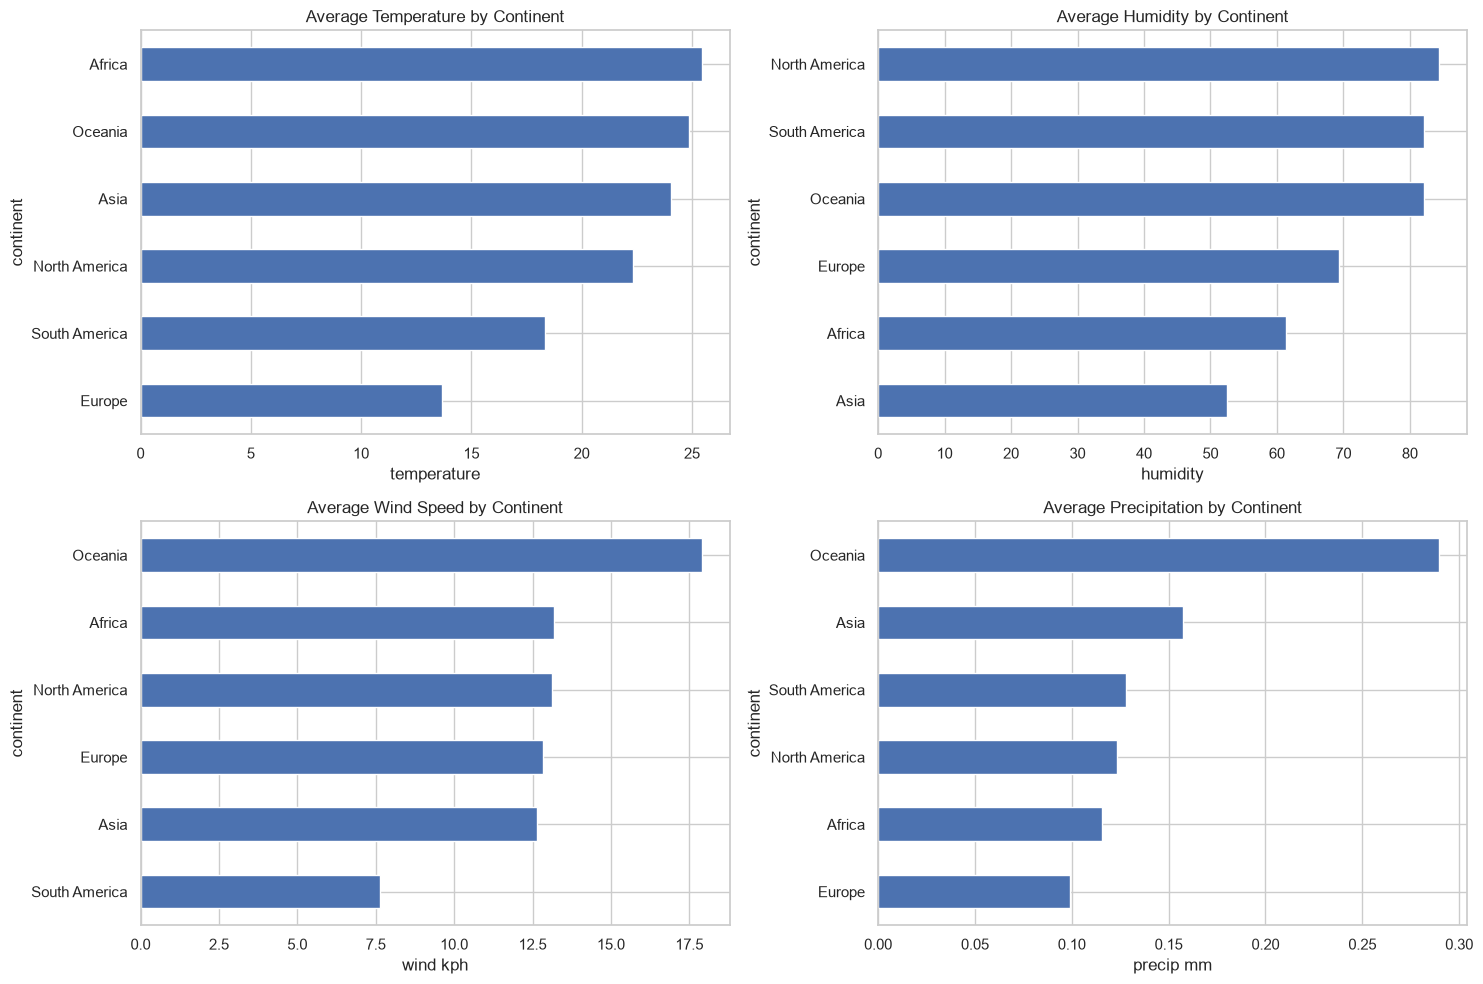

In [36]:
continent_summary = df_geo.groupby("continent").agg(
    average_temperature=("temperature_celsius", "mean"),
    average_humidity=("humidity", "mean"),
    average_wind_kph=("wind_kph", "mean"),
    average_precip_mm=("precip_mm", "mean"),
    locations=("location_name", "nunique"),
    observations=("temperature_celsius", "count")
).sort_values("average_temperature", ascending=False)
print("Weather comparison by continent:")
display(continent_summary.round(2))

country_summary = df_geo.groupby(["country_standard", "continent"]).agg(
    average_temperature=("temperature_celsius", "mean"),
    average_humidity=("humidity", "mean"),
    average_wind_kph=("wind_kph", "mean"),
    average_precip_mm=("precip_mm", "mean"),
    observations=("temperature_celsius", "count")
).sort_values("average_temperature", ascending=False)
print("Top and bottom country averages in this dataset:")
display(pd.concat([country_summary.head(10), country_summary.tail(10)]).round(2))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for column, title, ax in [
    ("average_temperature", "Average Temperature by Continent", axes[0,0]),
    ("average_humidity", "Average Humidity by Continent", axes[0,1]),
    ("average_wind_kph", "Average Wind Speed by Continent", axes[1,0]),
    ("average_precip_mm", "Average Precipitation by Continent", axes[1,1])
]:
    continent_summary[column].sort_values().plot(kind="barh", ax=ax)
    ax.set_title(title)
    ax.set_xlabel(column.replace("average_", "").replace("_", " "))
plt.tight_layout()
plt.show()

## 22. Final findings, caveats, and assessment coverage

In [37]:
print("PROJECT DATA SUMMARY")
print("--------------------")
print(f"Rows after cleaning: {len(df):,}")
print(f"Locations: {df['location_name'].nunique():,}")
print(f"Standardized countries: {df['country_standard'].nunique():,}")
print(f"Continents represented: {df['continent'].nunique():,}")
print(f"Observation period: {df['last_updated'].min().date()} to {df['last_updated'].max().date()}")
print(f"Selected forecasting location: {selected_location}")
print(f"Forecast test period: {y_test.index.min().date()} to {y_test.index.max().date()} ({len(y_test)} days)")
print("\nBest models by the reported test metrics:")
display(model_comparison.head(5).round(4))
print("\nForecasting protocol: rolling one-day-ahead; actual previous observations are available before the next prediction.")

PROJECT DATA SUMMARY
--------------------
Rows after cleaning: 128,638
Locations: 257
Standardized countries: 191
Continents represented: 6
Observation period: 2024-05-16 to 2026-03-10
Selected forecasting location: Vatican City
Forecast test period: 2025-11-04 to 2026-03-10 (127 days)

Best models by the reported test metrics:


,Rank,Model,MAE (°C),RMSE (°C),R2
0,1,Ensemble (Ridge + XGBoost),2.476,3.225,0.152
1,2,Linear Regression (Ridge CV tuned),2.504,3.332,0.095
2,3,ARIMA (rolling 1-step),2.688,3.468,0.019
3,4,Exponential Smoothing (rolling 1-step),2.709,3.492,0.006
4,5,Naive (previous day),2.827,3.696,-0.114



Forecasting protocol: rolling one-day-ahead; actual previous observations are available before the next prediction.


In [39]:
import os
import joblib

# Your project models folder
model_path = r"C:\Users\rohit\Downloads\Weather Trend Forecasting\Weather-Trend-Forecasting\models"

# Create folder if it does not exist
os.makedirs(model_path, exist_ok=True)

# Save your trained final model


print("Model saved successfully at:")
print(os.path.join(model_path, "weather_forecasting_model.pkl"))

Model saved successfully at:
C:\Users\rohit\Downloads\Weather Trend Forecasting\Weather-Trend-Forecasting\models\weather_forecasting_model.pkl


### Assessment coverage checklist

| Assessment requirement | Implemented section |
|---|---|
| Missing values, invalid values, outliers, normalization | Sections 4–6 |
| EDA trends, correlations, temperature and precipitation visuals | Section 7 |
| Forecasting model and metrics, using `last_updated` | Sections 9–16 |
| Advanced anomaly detection | Section 8 |
| Multiple forecasting models and ensemble | Sections 11–16 |
| Climate patterns and regional variation | Section 18 |
| Air-quality/weather correlations | Section 19 |
| Multiple feature-importance techniques | Section 17 |
| Spatial visualisation | Section 20 |
| Country and continent comparisons | Section 21 |

### Limitations to disclose

1. The data spans less than two years and does not support robust long-term climate-change inference.
2. The country and continent means represent the observations in this repository; coverage and sampling time may differ by place.
3. The forecasting experiment focuses on one location (Vatican City), so it does not demonstrate generalization to all cities.
4. The rolling one-day-ahead test assumes each actual day's observation becomes available before the next prediction. It is not a fixed-origin multi-day forecast.
5. IQR outliers and Isolation Forest anomalies are potential unusual observations, not automatically data errors. Only clearly invalid measurements are replaced.
6. Pollution correlations may be confounded by emissions, location, season, and other variables not present in the dataset.

### Final conclusion

The project completes the required data preparation, exploratory analysis, anomaly detection, model comparison, ensemble construction, and unique weather analyses. Forecast performance should be described using the actual test metrics, including whether the ensemble improves on the best individual model. Findings are exploratory and specific to the available dataset.